# Модель: конверсия визита «СберАвтоподписка» (без утечки)

**Задача** (бриф «Анализ сайта»): по данным визита — UTM-метки, устройство, гео, время — предсказать,
совершит ли посетитель **целевое действие** (заявка, звонок, диалог и т.п.). Метрика — **ROC-AUC, ориентир ≈ 0.65**.
Модель нужно сравнить с бейзлайном и упаковать в API, которое возвращает 0/1.

**Чего избегаем (утечка таргета).** Первая версия модели (ROC-AUC 0.895) училась на уровне хитов и подсматривала ответ:
1. `n_target_hits` — число целевых хитов в сессии, по сути сам ответ;
2. признаки, известные только после визита: `n_hits`, `n_unique_pages`, `session_total_sec`, `hit_sec`, `hit_number`;
3. случайный сплит по хитам — хиты одной сессии попадали и в train, и в valid.

**Здесь:**
- одна строка = один визит (сессия); `target = 1`, если в визите было хотя бы одно целевое действие;
- признаки — только то, что известно в момент начала визита (общий модуль `src/features.py`, его же использует API);
- две схемы проверки: **случайный стратифицированный сплит 70/30** (как в задании) и более строгий **сплит по времени** (учимся на ранних датах, проверяемся на последних — как в проде);
- финальная модель для API обучается на всех данных;
- сравнение: бейзлайн «конверсия канала» → логистическая регрессия → CatBoost.

In [19]:
import gc, json, os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier, Pool
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support, precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

root = Path(os.getcwd()).parent
sys.path.insert(0, str(root))
from src.features import TARGET_ACTIONS, CAT_FEATURES, NUM_FEATURES, build_features, session_targets

raw = root / 'data' / 'raw'
out = root / 'data' / 'models'
out.mkdir(parents=True, exist_ok=True)
FEATURES = CAT_FEATURES + NUM_FEATURES
print(len(FEATURES), 'признаков')

22 признаков


## 1. Таргет: было ли в визите целевое действие

In [20]:
hits = pd.read_pickle(raw / 'ga_hits.pkl')[['session_id', 'event_action']]
print(f'Хитов: {len(hits):,}')
print(hits.loc[hits['event_action'].astype(str).str.startswith('sub_'), 'event_action'].value_counts())

target = session_targets(hits)
print(f'Сессий в хитах: {len(target):,}, с целевым действием: {target.sum():,}')
del hits; gc.collect()

Хитов: 15,726,470
event_action
sub_landing                         1798117
sub_view_cars_click                  791515
sub_car_page                         130310
sub_header_link_click                 79192
sub_offer_click                       69291
sub_faq                               56034
sub_view_faq_click                    43232
sub_car_claim_click                   37928
sub_open_dialog_click                 25870
sub_submit_success                    18439
sub_car_claim_submit_click            12359
sub_footer_link_click                  3670
sub_call_number_click                  3653
sub_callback_submit_click              3074
sub_car_request_submit_click           2966
sub_account_page                       1613
sub_custom_question_submit_click        619
sub_banner_click                         74
sub_submit_error                         56
sub_custom_failed_submit_click           28
Name: count, dtype: int64
Сессий в хитах: 1,734,610, с целевым действием: 50,760


15251

## 2. Визиты и признаки

In [21]:
sessions = pd.read_pickle(raw / 'ga_sessions.pkl')
print(f'Визитов: {len(sessions):,}')

# Берём только визиты, по которым есть хиты: для остальных таргет неизвестен
sessions = sessions[sessions['session_id'].isin(target.index)].reset_index(drop=True)
y = sessions['session_id'].map(target).astype('int8')
visit_dt = pd.to_datetime(sessions['visit_date'], errors='coerce').dt.normalize() + \
           pd.to_timedelta(sessions['visit_time'].astype(str), errors='coerce')

X = build_features(sessions)
del sessions; gc.collect()
print(f'Визитов с хитами: {len(X):,}, конверсия: {y.mean():.4f}')
X.head()

Визитов: 1,860,042
Визитов с хитами: 1,732,266, конверсия: 0.0290


,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_browser,geo_country,...,device_category_os,visit_number,is_new_visitor,visit_hour,visit_weekday,is_weekend,is_organic,screen_w,screen_h,screen_ratio
0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,Chrome,Russia,...,mobile | Android,1,1,14,2,0,0,360.0,720.0,2.000000
1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,Samsung Internet,Russia,...,mobile | Android,1,1,8,6,1,0,385.0,854.0,2.218182
2,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,Chrome,Russia,...,mobile | Android,1,1,2,1,0,0,360.0,720.0,2.000000
3,kjsLglQLzykiRbcDiGcD,cpc,(missing),NOBKLgtuvqYWkXQHeYWM,(missing),mobile,(missing),Xiaomi,Chrome,Russia,...,mobile | (missing),1,1,5,5,1,0,393.0,786.0,2.000000
4,kjsLglQLzykiRbcDiGcD,cpc,(missing),(missing),(missing),mobile,(missing),Xiaomi,Chrome,Russia,...,mobile | (missing),2,0,5,5,1,0,393.0,786.0,2.000000


## 3. Короткий EDA по признакам модели
Конверсия по ключевым срезам и проверка линейной зависимости числовых признаков.

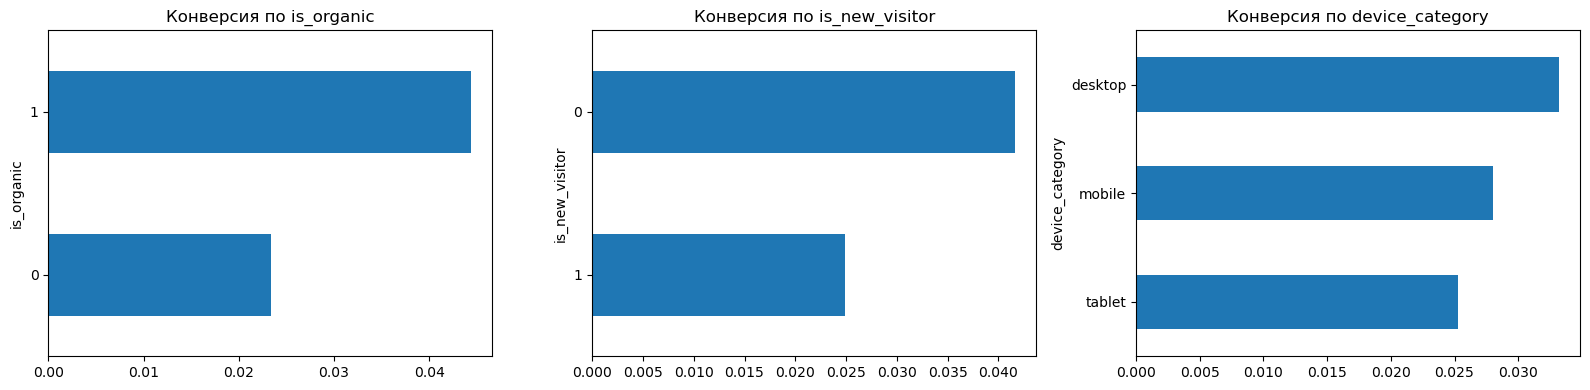

,CR,visits
utm_medium,,
cpm,0.010962,229791
stories,0.012032,10472
email,0.014176,28287
cpv,0.014715,7815
blogger_channel,0.020955,7731
cpc,0.023859,399395
smartbanner,0.027534,6501
banner,0.028764,525206
push,0.030314,27710


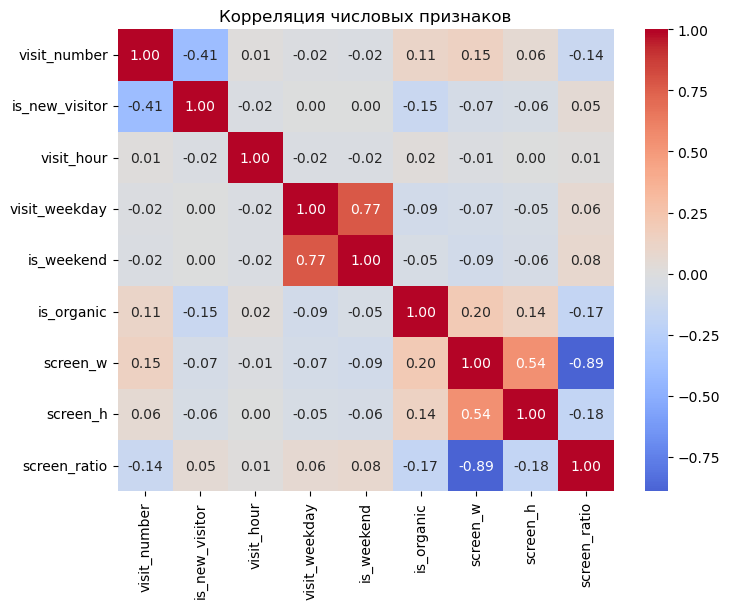

In [22]:
df_eda = X.assign(target=y)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['is_organic', 'is_new_visitor', 'device_category']):
    cr = df_eda.groupby(col)['target'].agg(['mean', 'size'])
    cr = cr[cr['size'] > 1000]['mean'].sort_values()
    cr.plot.barh(ax=ax, title=f'Конверсия по {col}')
plt.tight_layout(); plt.show()

top_medium = df_eda.groupby('utm_medium')['target'].agg(CR='mean', visits='size').query('visits > 5000').sort_values('CR')
display(top_medium)

corr = X[NUM_FEATURES].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляция числовых признаков'); plt.show()

*Сильно связанные пары (|r| > 0.8), например `visit_number`/`is_new_visitor` или `visit_weekday`/`is_weekend`,
не мешают бустингу, но для логистической регрессии их стоит учитывать — они дублируют информацию.*

## 4. Функции обучения и оценки
Три модели на одной и той же схеме проверки:
- **бейзлайн** — конверсия канала «источник + тип трафика», посчитанная на train;
- **логистическая регрессия** — one-hot категорий + масштабированные числа;
- **CatBoost** — ранняя остановка по отдельной валидации внутри train.

In [23]:
CB_PARAMS = dict(learning_rate=0.06, depth=6, l2_leaf_reg=10, eval_metric='AUC',
                 random_seed=42, thread_count=-1, verbose=0)

def fit_logreg(Xa, ya, n_max=500_000):
    idx = Xa.sample(min(n_max, len(Xa)), random_state=42).index
    pipe = make_pipeline(
        ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=200), CAT_FEATURES),
            ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM_FEATURES),
        ]),
        LogisticRegression(max_iter=1000, C=0.5),
    )
    return pipe.fit(Xa.loc[idx], ya.loc[idx])

def evaluate(Xtr, ytr, Xva, yva, Xte, yte, name):
    res = {}
    cr_map = ytr.groupby(Xtr['source_medium']).mean()
    res['Бейзлайн: CR канала'] = roc_auc_score(yte, Xte['source_medium'].map(cr_map).fillna(ytr.mean()))
    res['Логистическая регрессия'] = roc_auc_score(yte, fit_logreg(Xtr, ytr).predict_proba(Xte)[:, 1])
    cb = CatBoostClassifier(iterations=3000, od_type='Iter', od_wait=150, **CB_PARAMS)
    cb.fit(Pool(Xtr, ytr, cat_features=CAT_FEATURES),
           eval_set=Pool(Xva, yva, cat_features=CAT_FEATURES), use_best_model=True)
    p_va, p_te = cb.predict_proba(Xva)[:, 1], cb.predict_proba(Xte)[:, 1]
    res['CatBoost'] = roc_auc_score(yte, p_te)
    print(f'{name}: CatBoost best_iteration={cb.get_best_iteration()}, valid AUC={roc_auc_score(yva, p_va):.4f}')
    return pd.Series(res, name=name), cb, p_va, yva, p_te

## 5. Схема A — случайный стратифицированный сплит 70/30 (как в задании)

In [24]:
from sklearn.model_selection import train_test_split
Xtr_a, Xte_a, ytr_a, yte_a = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
Xfit_a, Xva_a, yfit_a, yva_a = train_test_split(Xtr_a, ytr_a, test_size=0.15, stratify=ytr_a, random_state=42)
res_a, cb_a, p_va_a, yva_a, p_te_a = evaluate(Xfit_a, yfit_a, Xva_a, yva_a, Xte_a, yte_a, 'Случайный 70/30')
res_a.round(4)

Случайный 70/30: CatBoost best_iteration=2998, valid AUC=0.6992


Бейзлайн: CR канала        0.6361
Логистическая регрессия    0.6812
CatBoost                   0.7048
Name: Случайный 70/30, dtype: float64

## 6. Схема B — сплит по времени 70/15/15 (строже: проверка на будущих датах)

In [25]:
order = visit_dt.sort_values(kind='stable').index
Xs, ys, ts = X.loc[order].reset_index(drop=True), y.loc[order].reset_index(drop=True), visit_dt.loc[order].reset_index(drop=True)
n = len(Xs); i1, i2 = int(n * 0.70), int(n * 0.85)
for name, s in {'train': slice(0, i1), 'valid': slice(i1, i2), 'test': slice(i2, n)}.items():
    print(f'{name:5s}: {len(ys.iloc[s]):>9,}  {ts.iloc[s].min():%Y-%m-%d} → {ts.iloc[s].max():%Y-%m-%d}  CR={ys.iloc[s].mean():.4f}')
res_b, cb_b, *_ = evaluate(Xs.iloc[:i1], ys.iloc[:i1], Xs.iloc[i1:i2], ys.iloc[i1:i2], Xs.iloc[i2:], ys.iloc[i2:], 'По времени')
res_b.round(4)

train: 1,212,586  2021-05-19 → 2021-11-15  CR=0.0326
valid:   259,840  2021-11-15 → 2021-12-09  CR=0.0213
test :   259,840  2021-12-09 → 2021-12-31  CR=0.0202
По времени: CatBoost best_iteration=172, valid AUC=0.6198


Бейзлайн: CR канала        0.5368
Логистическая регрессия    0.6277
CatBoost                   0.6283
Name: По времени, dtype: float64

## 7. Сравнение моделей (ROC-AUC на отложенном тесте)

In [26]:
results = pd.concat([res_a, res_b], axis=1).round(4)
results

,Случайный 70/30,По времени
Бейзлайн: CR канала,0.6361,0.5368
Логистическая регрессия,0.6812,0.6277
CatBoost,0.7048,0.6283


*Схема B даёт ниже, потому что поведение трафика меняется со временем (в декабре другие кампании и другая конверсия),
а модель видит только прошлое. Это честная оценка того, как модель будет работать в проде.*

## 8. Порог для ответа 0/1
API по брифу должно возвращать 0 или 1. Конверсия ~3%, поэтому порог 0.5 дал бы почти одни нули.
Порог подбираем по F1 на валидации схемы A и проверяем на её тесте. Дополнительно смотрим **лифт**:
во сколько раз конверсия среди визитов с ответом 1 выше средней.

In [27]:
prec, rec, thr = precision_recall_curve(yva_a, p_va_a)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
threshold = float(thr[np.nanargmax(f1[:-1])])
pred = (p_te_a >= threshold).astype(int)
p, r, f, _ = precision_recall_fscore_support(yte_a, pred, average='binary', zero_division=0)
lift = p / yte_a.mean()
print(f'Порог: {threshold:.4f}')
print(f'Тест A: precision={p:.3f}, recall={r:.3f}, F1={f:.3f}, доля «1»: {pred.mean():.2%}, лифт ×{lift:.1f}')

# Лифт по топ-долям визитов
top = pd.DataFrame({'p': p_te_a, 'y': yte_a.values}).sort_values('p', ascending=False)
for q in [0.05, 0.10, 0.20]:
    k = int(len(top) * q)
    print(f'Топ-{q:.0%} визитов по вероятности: конверсия {top.y.iloc[:k].mean():.3%} (лифт ×{top.y.iloc[:k].mean() / top.y.mean():.1f}), '
          f'ловим {top.y.iloc[:k].sum() / top.y.sum():.0%} всех конверсий')

Порог: 0.0605
Тест A: precision=0.093, recall=0.210, F1=0.129, доля «1»: 6.53%, лифт ×3.2
Топ-5% визитов по вероятности: конверсия 10.256% (лифт ×3.5), ловим 18% всех конверсий
Топ-10% визитов по вероятности: конверсия 8.124% (лифт ×2.8), ловим 28% всех конверсий
Топ-20% визитов по вероятности: конверсия 6.508% (лифт ×2.2), ловим 45% всех конверсий


## 9. Важность признаков (CatBoost, схема A)

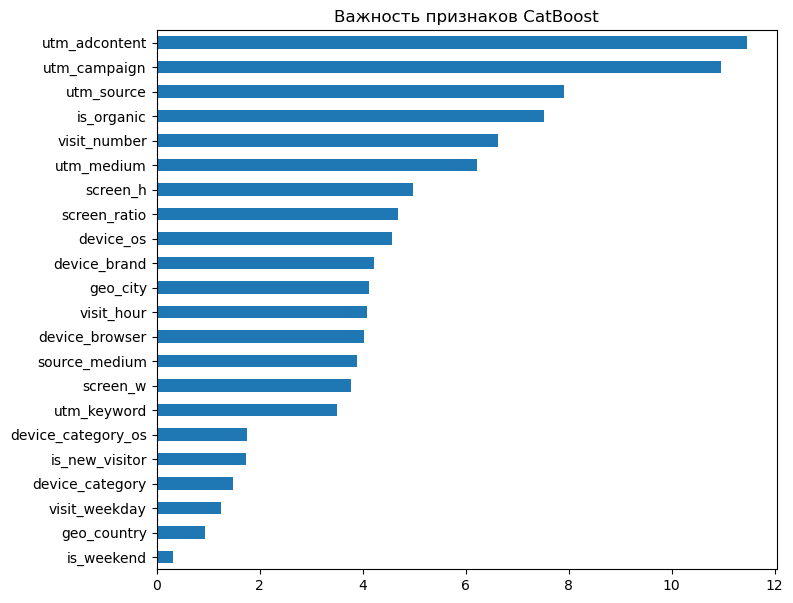

utm_adcontent         11.46
utm_campaign          10.96
utm_source             7.90
is_organic             7.51
visit_number           6.62
utm_medium             6.22
screen_h               4.98
screen_ratio           4.69
device_os              4.57
device_brand           4.23
geo_city               4.12
visit_hour             4.08
device_browser         4.03
source_medium          3.88
screen_w               3.78
utm_keyword            3.50
device_category_os     1.75
is_new_visitor         1.73
device_category        1.49
visit_weekday          1.24
geo_country            0.93
is_weekend             0.32
dtype: float64

In [28]:
imp = pd.Series(cb_a.get_feature_importance(), index=FEATURES).sort_values()
imp.plot.barh(figsize=(8, 7), title='Важность признаков CatBoost'); plt.show()
imp.sort_values(ascending=False).round(2)

## 10. Финальная модель на всех данных и сохранение

In [29]:
n_iter = int(cb_a.get_best_iteration() * 1.1) + 1
final = CatBoostClassifier(iterations=n_iter, **CB_PARAMS)
final.fit(Pool(X, y, cat_features=CAT_FEATURES))
final.save_model(str(out / 'catboost_sessions_v2.cbm'))

meta = {
    'model': 'catboost_sessions_v2.cbm',
    'level': 'session',
    'trained_on': 'all sessions with hits, 2021-05-19 → 2021-12-31',
    'iterations': n_iter,
    'target_actions': TARGET_ACTIONS,
    'features': FEATURES,
    'cat_features': CAT_FEATURES,
    'num_features': NUM_FEATURES,
    'roc_auc': {'test': round(float(res_a['CatBoost']), 4), 'test_time_split': round(float(res_b['CatBoost']), 4)},
    'roc_auc_all_models': results.to_dict(),
    'threshold': round(threshold, 6),
    'test_at_threshold': {'precision': round(p, 4), 'recall': round(r, 4), 'f1': round(f, 4), 'lift': round(lift, 2)},
}
(out / 'catboost_sessions_v2_meta.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(meta, ensure_ascii=False, indent=2))

{
  "model": "catboost_sessions_v2.cbm",
  "level": "session",
  "trained_on": "all sessions with hits, 2021-05-19 → 2021-12-31",
  "iterations": 3298,
  "target_actions": [
    "sub_car_claim_click",
    "sub_car_claim_submit_click",
    "sub_open_dialog_click",
    "sub_custom_question_submit_click",
    "sub_call_number_click",
    "sub_callback_submit_click",
    "sub_submit_success",
    "sub_car_request_submit_click"
  ],
  "features": [
    "utm_source",
    "utm_medium",
    "utm_campaign",
    "utm_adcontent",
    "utm_keyword",
    "device_category",
    "device_os",
    "device_brand",
    "device_browser",
    "geo_country",
    "geo_city",
    "source_medium",
    "device_category_os",
    "visit_number",
    "is_new_visitor",
    "visit_hour",
    "visit_weekday",
    "is_weekend",
    "is_organic",
    "screen_w",
    "screen_h",
    "screen_ratio"
  ],
  "cat_features": [
    "utm_source",
    "utm_medium",
    "utm_campaign",
    "utm_adcontent",
    "utm_keyword",
   

## 11. Выводы и рекомендации бизнесу

**Качество.** CatBoost — ROC-AUC **0.705** на случайном стратифицированном сплите 70/30 (ориентир 0.65 достигнут;
бейзлайн 0.636, логистическая регрессия 0.681). На более строгом сплите по времени — 0.628: в декабре меняются
кампании и падает конверсия, поэтому финальная модель обучена на всех данных.

**Польза.** В топ-10% визитов по оценке модели конверсия 8,1% (×2,8 к средней) — это 28% всех конверсий.

**Что влияет.** Объявление и кампания, источник трафика, органика/реклама, номер визита. Время и гео — слабо.

**Рекомендации:**
1. Органика и рефералы конвертируют почти вдвое лучше платного трафика (≈4,4% vs 2,3%; referral 6,0%).
   Слабые платные каналы — cpm, stories, email (1,1–1,4%): перераспределить бюджет в пользу кампаний с высокой оценкой модели.
2. Вернувшиеся посетители конвертируют в ~1,7 раза лучше новых (≈4,2% vs 2,5%) — усиливать ретаргетинг и push.
3. Посетителям из топ-10% по оценке сразу показывать форму обратного звонка или чат.
4. Десктоп конвертирует лучше мобильных (≈3,3% vs 2,8%) — проверить удобство мобильной формы заявки.
